# Linear Regression Baseline

Predicts a full day's 24 hourly GHI values from the previous day's 24 hours of weather data (ordinary least squares).

In [8]:
# Import libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from numpy.lib.stride_tricks import sliding_window_view
import joblib
import time

np.random.seed(42)


## 1. Load data and select features

In [9]:
# Load the dataset and add lag features

DATA_PATH = '../../../data/FYP_Cleaned_Dataset.csv'

df = pd.read_csv(DATA_PATH, parse_dates=['Datetime'])
df = df.sort_values(['State', 'Datetime']).reset_index(drop=True)


FEATURE_COLS = [
    'Latitude', 'Cloud_Coverage_Pct', 'Temp_Skin_C',
    'Relative_Humidity_Pct', 'Wind_Speed_10m_m_s_log',
    'Precipitable_Water_cm', 'Rainfall_mm_log', 'Is_Daylight',
    'Hour_sin', 'Hour_cos', 'Wind_Sine', 'Wind_Cosine',
    'GHI_lag_1h', 'GHI_lag_24h',
]
TARGET_COL = 'GHI_W_m2'

print(df.shape)
df.head()


(1314360, 19)


,Datetime,State,Latitude,GHI_W_m2,Cloud_Coverage_Pct,Temp_Skin_C,Relative_Humidity_Pct,Wind_Direction_10m_deg,Precipitable_Water_cm,Hour,Is_Daylight,Hour_sin,Hour_cos,Wind_Sine,Wind_Cosine,Rainfall_mm_log,Wind_Speed_10m_m_s_log,GHI_lag_1h,GHI_lag_24h
0,2016-01-02 00:00:00,Johor (Johor Bahru),1.4927,0.0,99.25,25.83,94.15,25.5,5.89,0,0,0.000000,1.000000,0.430511,0.902585,2.401525,1.704748,0.0,0.0
1,2016-01-02 01:00:00,Johor (Johor Bahru),1.4927,0.0,99.99,25.74,94.17,22.7,5.93,1,0,0.258819,0.965926,0.385906,0.922538,2.200552,1.697449,0.0,0.0
2,2016-01-02 02:00:00,Johor (Johor Bahru),1.4927,0.0,99.52,25.67,94.39,19.8,5.92,2,0,0.500000,0.866025,0.338738,0.940881,1.908060,1.658228,0.0,0.0
3,2016-01-02 03:00:00,Johor (Johor Bahru),1.4927,0.0,99.59,25.59,94.53,17.0,5.94,3,0,0.707107,0.707107,0.292372,0.956305,1.964311,1.615420,0.0,0.0
4,2016-01-02 04:00:00,Johor (Johor Bahru),1.4927,0.0,99.58,25.49,94.72,14.7,5.96,4,0,0.866025,0.500000,0.253758,0.967268,2.271094,1.553925,0.0,0.0


## 2. Split data into train/val/test

In [10]:
# Split each state's data chronologically (70% train, 10% val, 20% test)

TRAIN_FRAC = 0.7
VAL_FRAC = 0.1

def split_state(group):
    n = len(group)
    train_end = int(n * TRAIN_FRAC)
    val_end = int(n * (TRAIN_FRAC + VAL_FRAC))
    return group.iloc[:train_end], group.iloc[train_end:val_end], group.iloc[val_end:]

train_parts, val_parts, test_parts = [], [], []
for state, group in df.groupby('State', sort=False):
    tr, va, te = split_state(group)
    train_parts.append(tr); val_parts.append(va); test_parts.append(te)

train_df = pd.concat(train_parts).reset_index(drop=True)
val_df = pd.concat(val_parts).reset_index(drop=True)
test_df = pd.concat(test_parts).reset_index(drop=True)

print('Train:', train_df.shape, train_df['Datetime'].min(), '-', train_df['Datetime'].max())
print('Val:  ', val_df.shape, val_df['Datetime'].min(), '-', val_df['Datetime'].max())
print('Test: ', test_df.shape, test_df['Datetime'].min(), '-', test_df['Datetime'].max())


Train: (920040, 19) 2016-01-02 00:00:00 - 2022-12-31 15:00:00
Val:   (131445, 19) 2022-12-31 16:00:00 - 2023-12-31 18:00:00
Test:  (262875, 19) 2023-12-31 19:00:00 - 2025-12-30 23:00:00


## 3. Scale features and target

In [11]:
# Fit scalers on train data and apply to all splits

x_scaler = MinMaxScaler(feature_range=(0, 1))
y_scaler = MinMaxScaler(feature_range=(0, 1))

x_scaler.fit(train_df[FEATURE_COLS])
y_scaler.fit(train_df[[TARGET_COL]])

def scale(frame):
    frame = frame.copy()
    frame[FEATURE_COLS] = x_scaler.transform(frame[FEATURE_COLS])
    frame[TARGET_COL + '_scaled'] = y_scaler.transform(frame[[TARGET_COL]])
    return frame

train_scaled = scale(train_df)
val_scaled = scale(val_df)
test_scaled = scale(test_df)


## 4. Build input/output windows

In [12]:
# Build 24h input windows and 24h target windows, flattened for Linear Regression

WINDOW_SIZE = 24
OUTPUT_HORIZON = 24  # predict the whole next day at once

def build_multistep_arrays(frame, stride=1):
    X_list, y_list = [], []
    for _, group in frame.groupby('State', sort=False):
        group = group.sort_values('Datetime')
        n = len(group)
        if n <= WINDOW_SIZE + OUTPUT_HORIZON:
            continue
        X = group[FEATURE_COLS].to_numpy(dtype='float32')
        y = group[TARGET_COL + '_scaled'].to_numpy(dtype='float32')

        # offset the arrays so each input window lines up with its own next-day target
        X_for_windowing = X[: n - OUTPUT_HORIZON]
        y_for_windowing = y[WINDOW_SIZE:]

        Xw = sliding_window_view(X_for_windowing, WINDOW_SIZE, axis=0)[::stride]
        Xw = Xw.transpose(0, 2, 1).reshape(Xw.shape[0], -1)
        yw = sliding_window_view(y_for_windowing, OUTPUT_HORIZON, axis=0)[::stride]

        X_list.append(Xw)
        y_list.append(yw)

    return np.concatenate(X_list, axis=0), np.concatenate(y_list, axis=0)

X_train, y_train = build_multistep_arrays(train_scaled, stride=1)
X_val, y_val = build_multistep_arrays(val_scaled, stride=1)
X_test, y_test = build_multistep_arrays(test_scaled, stride=1)

print('X_train:', X_train.shape, 'y_train:', y_train.shape)
print('X_val:  ', X_val.shape, 'y_val:  ', y_val.shape)
print('X_test: ', X_test.shape, 'y_test: ', y_test.shape)


X_train: (919335, 336) y_train: (919335, 24)
X_val:   (130740, 336) y_val:   (130740, 24)
X_test:  (262170, 336) y_test:  (262170, 24)


## 5. Define the model

In [13]:
# Create the Linear Regression model

model = LinearRegression()
print(model)
print(model.get_params())


LinearRegression()
{'copy_X': True, 'fit_intercept': True, 'n_jobs': None, 'positive': False, 'tol': 1e-06}


## 6. Train the model

In [14]:
# Train the model and evaluate on validation set

train_start = time.time()
model.fit(X_train, y_train)
train_duration_sec = time.time() - train_start

print(f'Training time: {train_duration_sec:.2f} sec')

val_pred_scaled = model.predict(X_val)
val_mae_scaled = mean_absolute_error(y_val, val_pred_scaled)
val_rmse_scaled = np.sqrt(mean_squared_error(y_val, val_pred_scaled))
print(f'Val MAE (scaled): {val_mae_scaled:.4f}  Val RMSE (scaled): {val_rmse_scaled:.4f}')

# Real-unit validation metrics (same units as test/rolling-origin)
val_true = y_scaler.inverse_transform(y_val.reshape(-1, 1)).reshape(y_val.shape)
val_pred = y_scaler.inverse_transform(val_pred_scaled.reshape(-1, 1)).reshape(val_pred_scaled.shape)
val_pred = np.clip(val_pred, 0, None)

val_mae = mean_absolute_error(val_true.flatten(), val_pred.flatten())
val_rmse = np.sqrt(mean_squared_error(val_true.flatten(), val_pred.flatten()))
val_r2 = r2_score(val_true.flatten(), val_pred.flatten())
val_mbe = float(np.mean(val_pred.flatten() - val_true.flatten()))
val_nrmse = val_rmse / np.mean(val_true.flatten()) * 100
print(f'Val (real units)   MAE: {val_mae:.4f}  RMSE: {val_rmse:.4f}  R2: {val_r2:.4f}  MBE: {val_mbe:.4f}  nRMSE: {val_nrmse:.2f}%  (W/m²)')


Training time: 39.09 sec
Val MAE (scaled): 0.0413  Val RMSE (scaled): 0.0682
Val (real units)   MAE: 38.3615  RMSE: 70.9973  R2: 0.9328  MBE: 3.2324  nRMSE: 35.04%  (W/m²)


## 7. Evaluate on test set

In [15]:
# Predict on test set and compute pooled + per-horizon metrics

y_pred_scaled = model.predict(X_test)  # (n, 24)

y_true = y_scaler.inverse_transform(y_test.reshape(-1, 1)).reshape(y_test.shape)
y_pred = y_scaler.inverse_transform(y_pred_scaled.reshape(-1, 1)).reshape(y_pred_scaled.shape)
y_pred = np.clip(y_pred, 0, None)

mae = mean_absolute_error(y_true.flatten(), y_pred.flatten())
rmse = np.sqrt(mean_squared_error(y_true.flatten(), y_pred.flatten()))
r2 = r2_score(y_true.flatten(), y_pred.flatten())
mbe = float(np.mean(y_pred.flatten() - y_true.flatten()))
nrmse = rmse / np.mean(y_true.flatten()) * 100
print(f'Test (all origins, all horizons pooled) MAE: {mae:.4f}  RMSE: {rmse:.4f}  R2: {r2:.4f}  MBE: {mbe:.4f}  nRMSE: {nrmse:.2f}%  (W/m²)')

test_horizon_rows = []
for h in range(OUTPUT_HORIZON):
    yt, yp = y_true[:, h], y_pred[:, h]
    test_horizon_rows.append({
        'horizon_h': h + 1,
        'mae': mean_absolute_error(yt, yp),
        'rmse': np.sqrt(mean_squared_error(yt, yp)),
        'r2': r2_score(yt, yp),
    })
test_horizon_df = pd.DataFrame(test_horizon_rows)
test_horizon_df


Test (all origins, all horizons pooled) MAE: 38.9025  RMSE: 72.0926  R2: 0.9310  MBE: 2.7444  nRMSE: 35.51%  (W/m²)


,horizon_h,mae,rmse,r2
0,1,28.130466,48.318185,0.968988
1,2,34.093864,58.941744,0.953852
2,3,37.284321,65.295759,0.943366
3,4,38.797176,68.880246,0.936977
4,5,39.397827,70.750776,0.933507
5,6,39.557667,71.713075,0.931686
6,7,39.572414,72.260316,0.930639
7,8,39.552170,72.683217,0.929823
8,9,39.532570,73.088603,0.929037
9,10,39.581676,73.467341,0.928303


In [16]:
# Compute a persistence baseline for comparison ("tomorrow looks like today")

baseline_true_parts, baseline_pred_parts = [], []
for _, group in test_df.groupby('State', sort=False):
    group = group.sort_values('Datetime')
    values = group[TARGET_COL].to_numpy()
    n = len(values)
    if n <= WINDOW_SIZE + OUTPUT_HORIZON:
        continue
    windows = sliding_window_view(values, WINDOW_SIZE + OUTPUT_HORIZON)
    baseline_pred_parts.append(windows[:, :WINDOW_SIZE])
    baseline_true_parts.append(windows[:, WINDOW_SIZE:])

baseline_true = np.concatenate(baseline_true_parts).flatten()
baseline_pred = np.concatenate(baseline_pred_parts).flatten()
baseline_mae = mean_absolute_error(baseline_true, baseline_pred)
baseline_rmse = np.sqrt(mean_squared_error(baseline_true, baseline_pred))

print(f'Persistence (D+1 = D) baseline MAE: {baseline_mae:.4f}  RMSE: {baseline_rmse:.4f}')
print(f'Improvement over baseline: MAE {(baseline_mae-mae)/baseline_mae*100:.2f}%  RMSE {(baseline_rmse-rmse)/baseline_rmse*100:.2f}%')


Persistence (D+1 = D) baseline MAE: 43.7046  RMSE: 94.1648
Improvement over baseline: MAE 10.99%  RMSE 23.44%


## 8. Plot predicted vs actual, pooled across all 15 states (validation + test period)

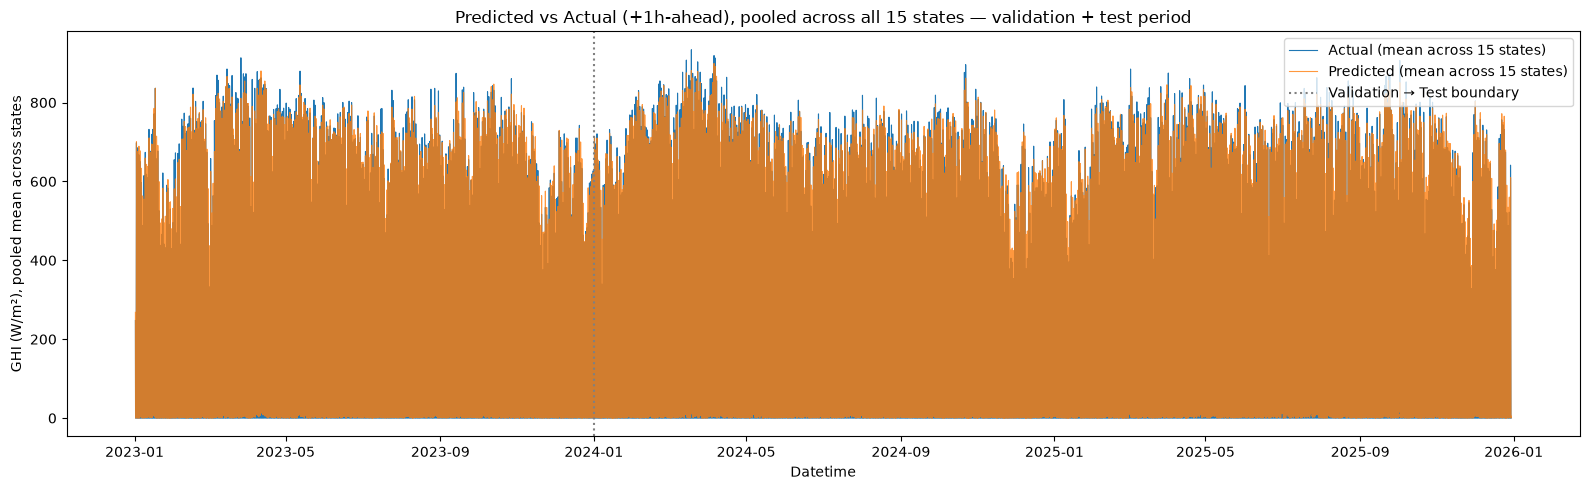

In [17]:
# Build the model's +1h-ahead prediction vs actual for every state,
# across the validation + test period (chronologically continuous),
# then average across all 15 states at each timestamp -- one pooled
# overview instead of 15 separate per-state subplots.

valtest_scaled = pd.concat([val_scaled, test_scaled]).sort_values(['State', 'Datetime'])
states = sorted(valtest_scaled["State"].unique())

per_state_series = []
for state in states:
    state_data = valtest_scaled[valtest_scaled['State'] == state].sort_values('Datetime')
    X_state = state_data[FEATURE_COLS].to_numpy(dtype='float32')  # already scaled
    actual_state = state_data[TARGET_COL].to_numpy(dtype='float32')  # real units
    dt_state = state_data['Datetime'].to_numpy()

    n = len(X_state)
    if n <= WINDOW_SIZE + OUTPUT_HORIZON:
        continue

    n_windows = n - WINDOW_SIZE - OUTPUT_HORIZON + 1
    Xw = sliding_window_view(X_state[: n - OUTPUT_HORIZON], WINDOW_SIZE, axis=0)[:n_windows]
    Xw = Xw.transpose(0, 2, 1).reshape(n_windows, -1)

    pred_scaled = model.predict(Xw)[:, 0]  # +1h-ahead column only
    pred = y_scaler.inverse_transform(pred_scaled.reshape(-1, 1)).flatten()
    pred = np.clip(pred, 0, None)

    actual = actual_state[WINDOW_SIZE: WINDOW_SIZE + n_windows]
    dt_plot = dt_state[WINDOW_SIZE: WINDOW_SIZE + n_windows]

    per_state_series.append(pd.DataFrame({'Datetime': dt_plot, 'actual': actual, 'predicted': pred}))

# Pool: average actual/predicted across all 15 states at each timestamp
pooled = pd.concat(per_state_series).groupby('Datetime', as_index=False).mean()
pooled = pooled.sort_values('Datetime')

plt.figure(figsize=(16, 5))
plt.plot(pooled['Datetime'], pooled['actual'], label='Actual (mean across 15 states)', linewidth=0.8)
plt.plot(pooled['Datetime'], pooled['predicted'], label='Predicted (mean across 15 states)', alpha=0.8, linewidth=0.8)
plt.axvline(test_df['Datetime'].min(), color='gray', linestyle=':', label='Validation → Test boundary')
plt.xlabel('Datetime')
plt.ylabel('GHI (W/m²), pooled mean across states')
plt.title('Predicted vs Actual (+1h-ahead), pooled across all 15 states — validation + test period')
plt.legend()
plt.tight_layout()
plt.show()


## 8a. Same plot, zoomed to one month (so the two lines are actually distinguishable)

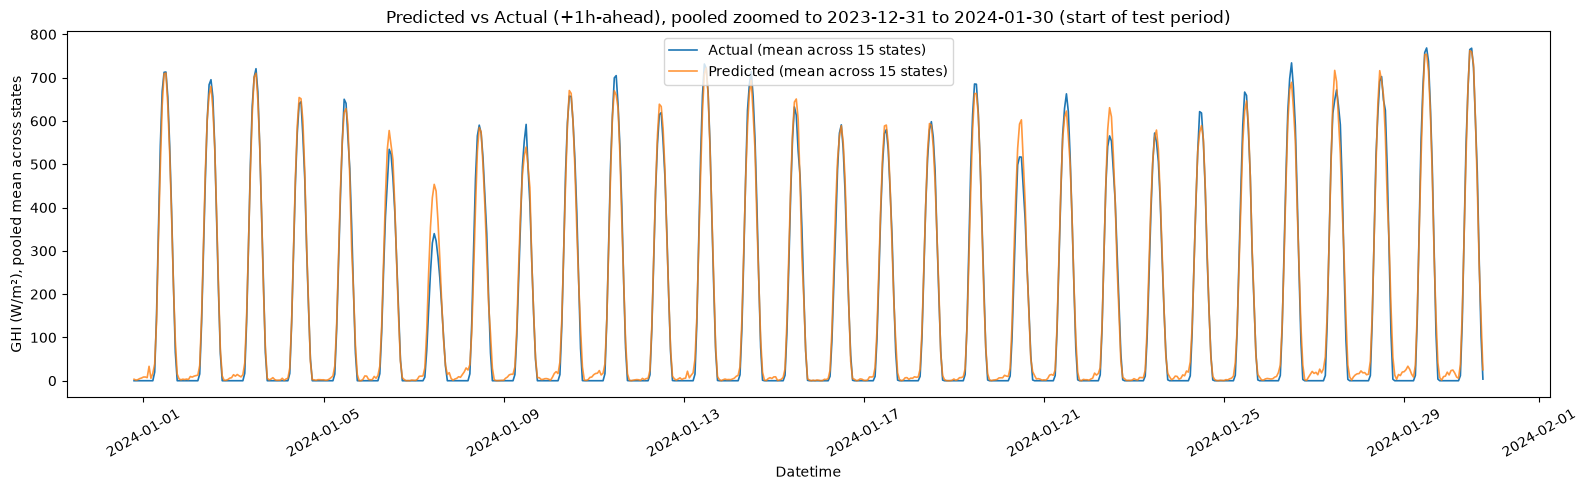

In [18]:
# The full validation+test plot above is too dense over ~3 years to tell
# the two lines apart -- zooming into the first 30 days of the test period
# (reuses the `pooled` dataframe already built above, no recomputation).

zoom_start = test_df['Datetime'].min()
zoom_end = zoom_start + pd.Timedelta(days=30)
zoomed = pooled[(pooled['Datetime'] >= zoom_start) & (pooled['Datetime'] < zoom_end)]

plt.figure(figsize=(16, 5))
plt.plot(zoomed['Datetime'], zoomed['actual'], label='Actual (mean across 15 states)', linewidth=1.2)
plt.plot(zoomed['Datetime'], zoomed['predicted'], label='Predicted (mean across 15 states)', alpha=0.8, linewidth=1.2)
plt.xlabel('Datetime')
plt.ylabel('GHI (W/m²), pooled mean across states')
plt.title(f'Predicted vs Actual (+1h-ahead), pooled zoomed to {zoom_start.date()} to {zoom_end.date()} (start of test period)')
plt.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


## 9. Save the model

In [20]:
# Save the trained model and scalers

joblib.dump(model, 'linreg_multistep_model.joblib')
joblib.dump(x_scaler, 'linreg_multistep_x_scaler.joblib')
joblib.dump(y_scaler, 'linreg_multistep_y_scaler.joblib')
print('saved.')


saved.


## 10. Rolling-origin evaluation (real day D -> predict real day D+1)

In [21]:
# Build real 24h input/output pairs for every day in the test period

TEST_START = test_df['Datetime'].min()

state_arrays = {}
for state, g in df.groupby('State', sort=False):
    g = g.sort_values('Datetime')
    g = g[g['Datetime'] >= TEST_START].reset_index(drop=True)
    state_arrays[state] = {
        'dt': g['Datetime'].to_numpy(),
        'X': g[FEATURE_COLS].to_numpy(dtype='float32'),
        'y': g[TARGET_COL].to_numpy(dtype='float32'),
    }

origin_windows, y_true_next_day, origin_meta = [], [], []

for state, arr in state_arrays.items():
    dt, X, y = arr['dt'], arr['X'], arr['y']
    n = len(dt)
    midnight_idx = np.where(pd.DatetimeIndex(dt).hour == 0)[0]
    for p in midnight_idx:
        if p + 2 * WINDOW_SIZE > n:
            continue
        origin_windows.append(X[p:p + WINDOW_SIZE])
        y_true_next_day.append(y[p + WINDOW_SIZE:p + 2 * WINDOW_SIZE])
        origin_meta.append((state, dt[p]))

origin_windows = np.stack(origin_windows)
y_true_next_day = np.stack(y_true_next_day)

print(f'{len(origin_meta)} origins across {len(state_arrays)} states')


10935 origins across 15 states


In [22]:
# Predict the next day's GHI for every origin in one forward pass

def scale_X_flat(batch):
    flat = batch.reshape(-1, len(FEATURE_COLS))
    scaled = x_scaler.transform(flat).reshape(batch.shape)
    return scaled.reshape(batch.shape[0], -1).astype('float32')

pred_scaled = model.predict(scale_X_flat(origin_windows))
y_pred_next_day = y_scaler.inverse_transform(pred_scaled.reshape(-1, 1)).reshape(pred_scaled.shape)
y_pred_next_day = np.clip(y_pred_next_day, 0, None)

print('direct rollout done (single forward pass, no recursion):', y_pred_next_day.shape)


direct rollout done (single forward pass, no recursion): (10935, 24)


/home/kelocker/miniconda3/envs/fyp/lib/python3.11/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(


In [23]:
# Compute overall and per-horizon metrics

y_true_flat = y_true_next_day.flatten()
y_pred_flat = y_pred_next_day.flatten()

mae = mean_absolute_error(y_true_flat, y_pred_flat)
rmse = np.sqrt(mean_squared_error(y_true_flat, y_pred_flat))
r2 = r2_score(y_true_flat, y_pred_flat)
mbe = float(np.mean(y_pred_flat - y_true_flat))
nrmse = rmse / np.mean(y_true_flat) * 100

print(f'Rolling-origin overall (all horizons pooled):')
print(f'  MAE:   {mae:.4f}')
print(f'  RMSE:  {rmse:.4f}')
print(f'  R2:    {r2:.4f}')
print(f'  MBE:   {mbe:.4f}')
print(f'  nRMSE: {nrmse:.2f}%')

horizon_rows = []
for h in range(WINDOW_SIZE):
    yt, yp = y_true_next_day[:, h], y_pred_next_day[:, h]
    horizon_rows.append({
        'horizon_h': h + 1,
        'mae': mean_absolute_error(yt, yp),
        'rmse': np.sqrt(mean_squared_error(yt, yp)),
        'r2': r2_score(yt, yp),
    })
horizon_df = pd.DataFrame(horizon_rows)
horizon_df


Rolling-origin overall (all horizons pooled):
  MAE:   40.3672
  RMSE:  74.3350
  R2:    0.9266
  MBE:   3.3732
  nRMSE: 36.61%


,horizon_h,mae,rmse,r2
0,1,6.422760,12.906525,0.000000
1,2,8.137030,16.416998,0.000000
2,3,9.544773,18.951914,0.000000
3,4,11.183175,21.077973,0.000000
4,5,11.537238,21.217749,0.000000
5,6,14.282928,23.689595,-226.818176
6,7,22.154142,28.080679,-0.391114
7,8,36.899105,46.971765,0.358081
8,9,67.529816,86.404069,0.266777
9,10,87.366875,113.831907,0.217037


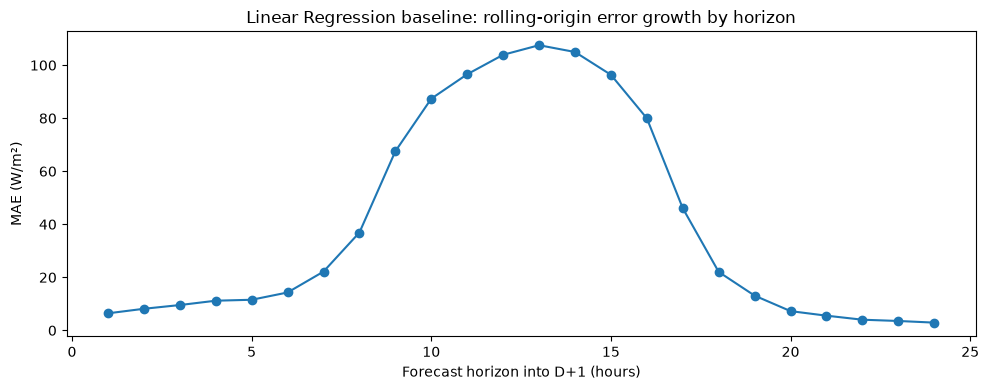

In [24]:
# Plot error growth by forecast horizon

plt.figure(figsize=(10, 4))
plt.plot(horizon_df['horizon_h'], horizon_df['mae'], marker='o')
plt.xlabel('Forecast horizon into D+1 (hours)')
plt.ylabel('MAE (W/m²)')
plt.title('Linear Regression baseline: rolling-origin error growth by horizon')
plt.tight_layout(); plt.show()


In [25]:
# Compute per-state metrics (so the pooled number can't hide one bad state)

state_of_origin = np.array([m[0] for m in origin_meta])
per_state_rows = []
for state in sorted(set(state_of_origin)):
    mask = state_of_origin == state
    yt = y_true_next_day[mask].flatten()
    yp = y_pred_next_day[mask].flatten()
    per_state_rows.append({
        'state': state, 'n_origins': int(mask.sum()),
        'mae': mean_absolute_error(yt, yp),
        'rmse': np.sqrt(mean_squared_error(yt, yp)),
        'r2': r2_score(yt, yp),
    })
per_state_df = pd.DataFrame(per_state_rows)
per_state_df


,state,n_origins,mae,rmse,r2
0,Johor (Johor Bahru),729,45.784538,87.790789,0.886595
1,Kedah (Alor Setar),729,39.255093,70.878806,0.934383
2,Kelantan (Kota Bharu),729,45.671246,83.337080,0.916686
3,Kuala Lumpur,729,35.030563,65.295501,0.938549
4,Melaka (Bandar Melaka),729,38.770569,69.680097,0.930115
5,Negeri Sembilan (Seremban),729,41.065647,75.809482,0.926252
6,Pahang (Kuantan),729,42.796230,80.487522,0.915994
7,Penang (George Town),729,38.576340,71.311836,0.936943
8,Perak (Ipoh),729,34.487469,62.042429,0.946703
9,Perlis (Kangar),729,40.400391,71.080284,0.934010


## 10b. Actual vs. predicted, one concrete forecast example

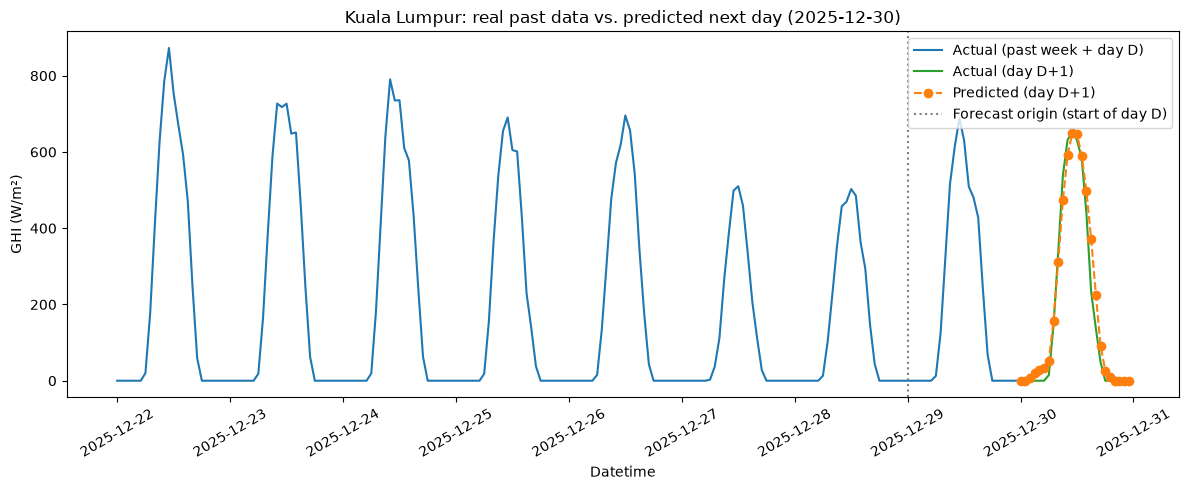

In [26]:
# One concrete example: real past week (actual) -> the model's
# predicted next day, shown as a distinct continuation. The real
# actual next day is overlaid too (in green), since ground truth
# exists for every origin in the test period -- shows how close the
# prediction actually was.

EXAMPLE_STATE = 'Kuala Lumpur'
N_PAST_DAYS = 7

example_indices = [i for i, m in enumerate(origin_meta) if m[0] == EXAMPLE_STATE]
example_idx = example_indices[-1]  # most recent origin for this state

arr = state_arrays[EXAMPLE_STATE]
origin_dt = origin_meta[example_idx][1]
origin_pos = np.where(arr['dt'] == origin_dt)[0][0]

past_start = max(0, origin_pos - N_PAST_DAYS * WINDOW_SIZE)
past_dt = arr['dt'][past_start:origin_pos + WINDOW_SIZE]        # past week + day D
past_actual = arr['y'][past_start:origin_pos + WINDOW_SIZE]

next_day_dt = arr['dt'][origin_pos + WINDOW_SIZE:origin_pos + 2 * WINDOW_SIZE]  # day D+1
next_day_actual = y_true_next_day[example_idx]
next_day_pred = y_pred_next_day[example_idx]

plt.figure(figsize=(12, 5))
plt.plot(past_dt, past_actual, color='tab:blue', label='Actual (past week + day D)')
plt.plot(next_day_dt, next_day_actual, color='tab:green', label='Actual (day D+1)')
plt.plot(next_day_dt, next_day_pred, color='tab:orange', linestyle='--', marker='o', label='Predicted (day D+1)')
plt.axvline(arr['dt'][origin_pos], color='gray', linestyle=':', label='Forecast origin (start of day D)')
plt.xlabel('Datetime')
plt.ylabel('GHI (W/m²)')
plt.title(f'{EXAMPLE_STATE}: real past data vs. predicted next day ({pd.Timestamp(next_day_dt[0]).date()})')
plt.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


In [27]:
# Save results to CSV

horizon_df.to_csv('rolling_origin_direct_by_horizon.csv', index=False)
per_state_df.to_csv('rolling_origin_direct_by_state.csv', index=False)
print('saved rolling_origin_direct_by_horizon.csv, rolling_origin_direct_by_state.csv')


saved rolling_origin_direct_by_horizon.csv, rolling_origin_direct_by_state.csv
